# Pseudo-bulk Hi-C: compartments per cell type, at matched depth

A single cell's Hi-C map holds tens of thousands of contacts — far too few to call compartments, domains or
loops.  Summed over the cells of a group (a cell type, a cluster, a condition), the maps become **pseudo-bulk**
maps that the bulk callers read.  This tutorial makes them straight from an atlas store read over HTTP, calls
compartments in each, and compares their strength between groups — which needs care, because the strength of
a shallow map is inflated, and groups of cells rarely have the same number of contacts.

- `uc.tl.pseudobulk(cd, "cell_type")` sums the per-cell maps linked to the cells per group, writes one
  ICE-balanced `.cool` per group and links it to `cd` as `pseudobulk.<group>`;
- `uc.tl.call_compartments(cd, method="eig", contacts=...)` and `uc.tl.compartment_strength` run on those maps
  as on any bulk map (the `hic_structures` tutorial);
- `pseudobulk(cd, groupby, ...)` with a `Series` cell → group sums any partition of the cells: here random
  subsets with the same number of contacts (`sample_cells_by_depth`), to compare groups at matched depth.

- **Data**: Wu et al. 2025, *Cell Discov.* (dscHi-C of the mouse cortex at 3, 12 and 23 months, GEO
  GSE285812): 32,777 cells with cell types, and each cell's contacts as a 1 Mb map, embedded in the atlas store
  `ds.load("dschic_aging_cortex")` — opened backed over HTTP, so only the parts used are fetched (here the
  contacts within chromosomes).  Gene density from the mm10 RefSeq annotation,
  `ds.fetch("mm10_refgene")` (UCSC, 13 MB).
- **Runtime**: about 3 min, mostly the HTTP reads of the per-cell maps.  The maps go to `tutorials/_out/`;
  a second run reuses them.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

import uchrom as uc
import uchrom.datasets as ds
from uchrom.fea import compute_annotation_features, open_map, sample_cells_by_depth
from uchrom.strc.comp import EigCompartmentParams

plt.rcParams["figure.dpi"] = 90
OUT = Path("_out") / "pseudobulk"; OUT.mkdir(parents=True, exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
T0 = time.time()

cd = ds.load("dschic_aging_cortex")       # the atlas store, backed, over HTTP
print(cd)
cells = cd.cells
cells.groupby("cell_type").agg(cells=("n_contacts", "size"), contacts=("n_contacts", "sum"),
                               median_per_cell=("n_contacts", "median"), trans_fraction=("frac_trans", "median"))

ChromData (backed: dschic_aging_cortex.chromdata.zarr): n_spots=0, n_traces=0, n_cells=32777, n_bins=0
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['age', 'cell_type', 'subtype', 'barcode', 'n_reads', 'n_contacts_published', 'frac_trans', 'frac_cis_le20kb', 'frac_cis_ge20kb', 'frac_mitotic_band', 'n_contacts'] (32777 cells)
  cellm:   {'hic_pca': (32777, 30), 'hic_umap': (32777, 2)}
  uns:     ['genome_assembly', 'source', 'coordinate_status', 'linked_cool', 'linked_scool', 'embeddings']


,cells,contacts,median_per_cell,trans_fraction
cell_type,,,,
Astrocytes,4578,397417441,70926.5,0.272247
Excitatory neurons,16915,1267226592,63754.0,0.251614
Inhibitory interneurons,3026,249309436,72139.0,0.269764
Microglial cells,1589,124067255,61102.0,0.276810
Oligodendrocyte precursor cells,889,70396436,66423.0,0.282847
Oligodendrocytes,4759,399097272,64809.0,0.282165
Vascular leptomeningeal cells,1021,97334065,78238.0,0.287557


The cells have their cell type, age and contact statistics in `cd.cells`; their maps are embedded in the store
under the key `per_cell` (`cd.uns["linked_scool"]`).  The cell types differ almost 20-fold in total contacts.

## 1. One map per cell type

`pseudobulk` reads the embedded per-cell maps one chromosome partition at a time, for all the selected cells,
and adds them up by group as they stream in.  Compartments and their strength are computed within chromosomes,
so `trans=False` keeps the cis contacts only: the reads skip the partitions between pairs of chromosomes (in a
test run 30 s instead of 75 s for these seven maps) and each map is balanced chromosome by chromosome.  The maps are written to `out_dir`
(default for a store read over HTTP: the data directory) and linked to `cd`; the summary is also stored as
`cd.results["pseudobulk"]`.

In [2]:
t0 = time.time()
summary = uc.tl.pseudobulk(cd, "cell_type", trans=False, out_dir=OUT)
print(f"{len(summary)} maps in {time.time() - t0:.0f} s")
display(summary[["group", "n_cells", "n_cis", "n_pixels", "key", "balanced"]])
{k: v for k, v in cd.uns["linked_cool"]["pseudobulk.Microglial cells"].items() if k != "path"}   # the link record

7 maps in 1 s


,group,n_cells,n_cis,n_pixels,key,balanced
0,Astrocytes,4578,289378575,177814,pseudobulk.Astrocytes,True
1,Excitatory neurons,16915,954212209,178123,pseudobulk.Excitatory neurons,True
2,Inhibitory interneurons,3026,182864591,177364,pseudobulk.Inhibitory interneurons,True
3,Microglial cells,1589,89950271,177312,pseudobulk.Microglial cells,True
4,Oligodendrocyte precursor cells,889,51019480,176518,pseudobulk.Oligodendrocyte precursor cells,True
5,Oligodendrocytes,4759,284498470,177816,pseudobulk.Oligodendrocytes,True
6,Vascular leptomeningeal cells,1021,69431914,177069,pseudobulk.Vascular leptomeningeal cells,True


{'format': 'cool',
 'label': 'Pseudo-bulk: Microglial cells (1,589 cells)',
 'genome_assembly': 'mm10',
 'bin_size': 1000000,
 'pseudobulk_of': 'per_cell',
 'groupby': 'cell_type',
 'group': 'Microglial cells',
 'n_cells': 1589,
 'n_contacts': 89950271,
 'trans': False,
 'balanced': True}

## 2. Orienting the eigenvectors the same way in every map

The sign of an eigenvector is arbitrary, and on some chromosomes the compartment pattern is not the eigenvector
with the largest eigenvalue.  `call_compartments` orients each eigenvector by its correlation with a
`phasing` track; with `EigCompartmentParams(sort_by_phasing=True)` the eigenvector that correlates best becomes
E1.  For the human genome the track is usually GC content; here it is **gene density** — RefSeq genes per
1 Mb bin, from `compute_annotation_features` on the bins of the maps.  To orient all cell types the same way,
the gene density orients the compartments of **all cells**, and the all-cells E1 orients every cell type:
`phasing="compartments.all"`, the key of that compartment table.  The all-cells map is made the same way as the
cell-type maps — `pseudobulk(cd)` without a grouping, cis contacts, balanced per chromosome (the store's own
all-cells map, key `bulk`, holds all contacts and is balanced genome-wide).  We use the autosomes.

In [3]:
AUTOSOMES = [f"chr{i}" for i in range(1, 20)]
EIG = EigCompartmentParams(sort_by_phasing=True)

t0 = time.time()
uc.tl.pseudobulk(cd, trans=False, out_dir=OUT)                          # all cells: pseudobulk.all
print(f"all cells: {time.time() - t0:.0f} s")
bins = open_map(cd, "pseudobulk.all").bins()[:][["chrom", "start", "end"]]
genes = compute_annotation_features(bins, ds.fetch("mm10_refgene"), features=["gene_count"])   # chrom, start, end, gene_count
comp_all = uc.tl.call_compartments(cd, method="eig", contacts="pseudobulk.all", chrom=AUTOSOMES, phasing=genes,
                                   params=EIG, key_added="compartments.all")
ev = cd.results["compartments.all.eigvals"]
swapped = ev.loc[ev["eigval1"].abs() < ev["eigval2"].abs(), "region"].tolist()
print(f"E1 vs gene density (Spearman, per chromosome): median {ev['phasing_r1'].median():.2f}, "
      f"range {ev['phasing_r1'].min():.2f}-{ev['phasing_r1'].max():.2f}; "
      f"compartment eigenvector not the leading one on {', '.join(swapped)}")

all cells: 1 s


E1 vs gene density (Spearman, per chromosome): median 0.67, range 0.49-0.85; compartment eigenvector not the leading one on chr6, chr7, chr9, chr13


## 3. Compartments and their strength per cell type

Each cell-type map gets its own eigenvectors, oriented by the all-cells E1, and its saddle strength
(`(AA + BB) / (AB + BA)` from the corners of the saddle plot; see the `hic_structures` tutorial).
The table also gives, per cell type, how well its E1 matches the all-cells E1 chromosome by chromosome.

In [4]:
SHORT = {"Astrocytes": "Astro", "Excitatory neurons": "Exc", "Inhibitory interneurons": "Inh",
         "Microglial cells": "Micro", "Oligodendrocyte precursor cells": "OPC", "Oligodendrocytes": "Oligo",
         "Vascular leptomeningeal cells": "VLMC"}
rows, E1 = [], {"all": comp_all.set_index(["chrom", "start"])["E1"]}
for g, key, n_cis in zip(summary["group"], summary["key"], summary["n_cis"]):
    comp = uc.tl.call_compartments(cd, method="eig", contacts=key, chrom=AUTOSOMES, phasing="compartments.all",
                                   params=EIG, key_added=f"compartments.{g}")
    s = uc.tl.compartment_strength(cd, contacts=key, compartments=f"compartments.{g}",
                                   key_added=f"compartment_strength.{g}")
    r = cd.results[f"compartments.{g}.eigvals"]["phasing_r1"]
    E1[SHORT[g]] = comp.set_index(["chrom", "start"])["E1"]
    regions = cd.results[f"compartments.{g}.eigvals"]["region"]
    rows.append({"cell type": g, "cis contacts (M)": n_cis / 1e6, "A fraction": (comp["E1"] > 0).mean(),
                 "r with all-cells E1 (median)": r.median(), "(min)": r.min(), "(min on)": regions[r.idxmin()],
                 "strength": s["strength"], "AA": s["AA"], "BB": s["BB"], "AB": s["AB"]})
full = pd.DataFrame(rows).set_index("cell type")
full.round(2)

,cis contacts (M),A fraction,r with all-cells E1 (median),(min),(min on),strength,AA,BB,AB
cell type,,,,,,,,,
Astrocytes,289.38,0.48,0.97,0.76,chr6,3.52,2.04,1.39,0.48
Excitatory neurons,954.21,0.51,0.97,0.83,chr3,3.06,2.07,1.19,0.52
Inhibitory interneurons,182.86,0.54,0.96,0.77,chr13,2.99,2.13,1.11,0.52
Microglial cells,89.95,0.48,0.93,0.51,chr9,4.14,2.02,1.55,0.43
Oligodendrocyte precursor cells,51.02,0.49,0.96,0.55,chr9,4.11,2.15,1.61,0.46
Oligodendrocytes,284.50,0.48,0.97,0.42,chr9,3.75,1.96,1.55,0.47
Vascular leptomeningeal cells,69.43,0.51,0.95,0.43,chr9,3.54,1.97,1.51,0.49


E1 between cell types: Pearson r 0.84-0.98 (closest: ('Exc', 'Inh'), farthest: ('Inh', 'VLMC'))


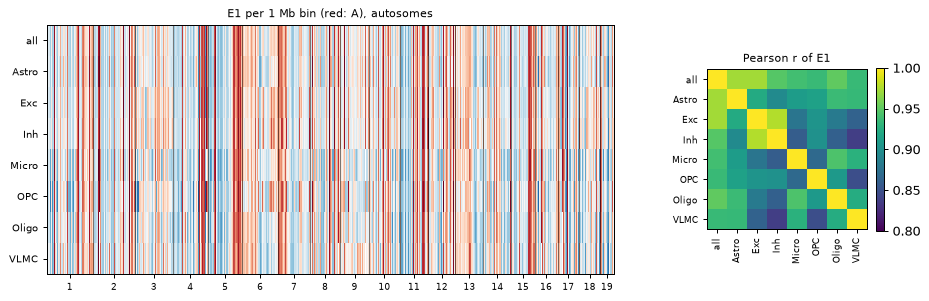

In [5]:
E1 = pd.DataFrame(E1).reindex(E1["all"].index)                       # chromosomes in their natural order
C = E1.drop(columns="all").corr()
off = C.to_numpy()[np.triu_indices(len(C), 1)]
print(f"E1 between cell types: Pearson r {off.min():.2f}-{off.max():.2f} "
      f"(closest: {C.where(C < 1).stack().idxmax()}, farthest: {C.stack().idxmin()})")
fig = plt.figure(figsize=(12, 3.6))
gs = fig.add_gridspec(1, 2, width_ratios=[3.2, 1], wspace=0.25)
ax = fig.add_subplot(gs[0])
ax.imshow(E1.T.to_numpy(), aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(0, -1.5, 1.5), interpolation="none")
chrom = E1.index.get_level_values(0).to_numpy()
edges = np.flatnonzero(chrom[1:] != chrom[:-1]) + 0.5
for e in edges:
    ax.axvline(e, color="k", lw=0.4)
mids = [np.mean(np.flatnonzero(chrom == c)) for c in AUTOSOMES]
ax.set_xticks(mids, [c.removeprefix("chr") for c in AUTOSOMES], fontsize=7)
ax.set_yticks(range(E1.shape[1]), E1.columns, fontsize=8)
ax.set_title("E1 per 1 Mb bin (red: A), autosomes", fontsize=9)
ax2 = fig.add_subplot(gs[1])
C = E1.corr()
im = ax2.imshow(C, cmap="viridis", vmin=0.8, vmax=1)
ax2.set_xticks(range(len(C)), C.columns, rotation=90, fontsize=7); ax2.set_yticks(range(len(C)), C.columns, fontsize=7)
ax2.set_title("Pearson r of E1", fontsize=9)
fig.colorbar(im, ax=ax2, fraction=0.046)
plt.show()

The compartments are largely shared: genome-wide the E1 of every cell type correlates 0.84–0.98 with every
other, the two neuron types most closely.  Chromosome by chromosome the match with the all-cells E1 is high
(median 0.93–0.97); the lowest values are on chr9 for four cell types, and on chr6 and chr13 — chromosomes
where the compartment eigenvector is not the leading one (above).  The strength, however, ranges from about 3.0 in the neurons to about 4.1 in microglia and
OPCs — while the cell-type maps range from 51 M to 954 M cis contacts.  Is the difference a matter of depth?

## 4. Depth, and comparing at matched depth

Two things are measured from random subsets of cells, all in one `pseudobulk` call.
`sample_cells_by_depth(cd, groupby, n_contacts=)` shuffles the cells of each group and takes them until their
contacts reach the target, then draws the next set from the cells left, so no cell is in two sets; its `set`
column is the `groupby` of `pseudobulk`.  The maps hold cis contacts only, so the contacts counted are each
cell's cis contacts (its contacts times one minus its fraction of trans contacts, both in `cd.cells`):

1. **matched depth**: for every cell type at every age, up to three disjoint sets of 5 M cis contacts each
   (the warning names the groups too small for three);
2. **depth**: from the excitatory neurons not drawn yet (`cells=`), sets of 2, 5, 20, 50 and 200 M cis contacts.

Each subset map gets its own compartments (oriented by the all-cells E1, as above) and its strength; the
strength is also computed with the all-cells E1 as the track that groups the bins, which does not depend on
the eigenvector of the shallow map itself.

In [6]:
cis = cells["n_contacts"] * (1 - cells["frac_trans"])                  # cis contacts per cell
matched_sets = sample_cells_by_depth(cd, ["cell_type", "age"], n_contacts=5e6, replicates=3, contacts=cis, seed=0)
rest = cells.index[(cells["cell_type"] == "Excitatory neurons") & ~cells.index.isin(matched_sets.index)]
depth_sets = sample_cells_by_depth(cd, "cell_type", n_contacts=[2e6, 5e6, 20e6, 50e6, 200e6], contacts=cis,
                                   cells=rest, seed=1)
sets = pd.concat([matched_sets.assign(kind="matched"), depth_sets.assign(kind="depth")])
display(sets.drop_duplicates("set").head(4))

t0 = time.time()
subsets = uc.tl.pseudobulk(cd, sets["set"], trans=False, key_prefix="subset", out_dir=OUT)
print(f"{len(subsets)} maps from {len(sets):,} cells in {time.time() - t0:.0f} s")

/var/folders/tq/285915z105g568z0ss3ll7_w0000gn/T/ipykernel_65192/684533219.py:2: UserWarning: too few contacts for every set: Vascular leptomeningeal cells | 23 months (5M: 1 of 3), Oligodendrocyte precursor cells | 23 months (5M: 1 of 3)
  matched_sets = sample_cells_by_depth(cd, ["cell_type", "age"], n_contacts=5e6, replicates=3, contacts=cis, seed=0)


,group,n_contacts,replicate,set,kind
cell_id,,,,,
3m_TTCTGTAGTAAGCCTT,Excitatory neurons | 3 months,5000000.0,1,Excitatory neurons | 3 months | 1,matched
3m_AGGCCCAAGATACCAA,Excitatory neurons | 3 months,5000000.0,2,Excitatory neurons | 3 months | 2,matched
3m_TCCCACAGTATTCGCA,Excitatory neurons | 3 months,5000000.0,3,Excitatory neurons | 3 months | 3,matched
3m_GCCCAGAGTGATGCGA,Vascular leptomeningeal cells | 3 months,5000000.0,1,Vascular leptomeningeal cells | 3 months | 1,matched


64 maps from 10,424 cells in 1 s


In [7]:
info = sets.drop_duplicates("set").set_index("set")
rows = []
for g, key, n_cis in zip(subsets["group"], subsets["key"], subsets["n_cis"]):
    uc.tl.call_compartments(cd, method="eig", contacts=key, chrom=AUTOSOMES, phasing="compartments.all",
                            params=EIG, key_added=f"compartments.{g}")
    own = uc.tl.compartment_strength(cd, contacts=key, compartments=f"compartments.{g}", key_added=None)
    shared = uc.tl.compartment_strength(cd, contacts=key, compartments="compartments.all", key_added=None)
    cell_type, *age = info.loc[g, "group"].split(" | ")
    rows.append({"kind": info.loc[g, "kind"], "cell type": SHORT[cell_type], "age": age[0] if age else None,
                 "replicate": info.loc[g, "replicate"], "cis contacts": n_cis,
                 "strength": own["strength"], "strength (all-cells E1)": shared["strength"]})
res = pd.DataFrame(rows)
curve = res[res["kind"] == "depth"].sort_values("cis contacts")
exc = full.loc["Excitatory neurons"]
curve = pd.concat([curve, pd.DataFrame([{"cell type": "Exc", "cis contacts": exc["cis contacts (M)"] * 1e6,
                                         "strength": exc["strength"],
                                         "strength (all-cells E1)": uc.tl.compartment_strength(
                                             cd, contacts="pseudobulk.Excitatory neurons",
                                             compartments="compartments.all", key_added=None)["strength"]}])])
curve[["cis contacts", "strength", "strength (all-cells E1)"]].round(2)

,cis contacts,strength,strength (all-cells E1)
17,2026931.0,3.51,2.96
22,5027036.0,3.29,3.01
13,20015965.0,3.13,3.01
21,50029790.0,3.08,2.98
12,200128238.0,3.06,2.97
0,954212209.0,3.06,2.97


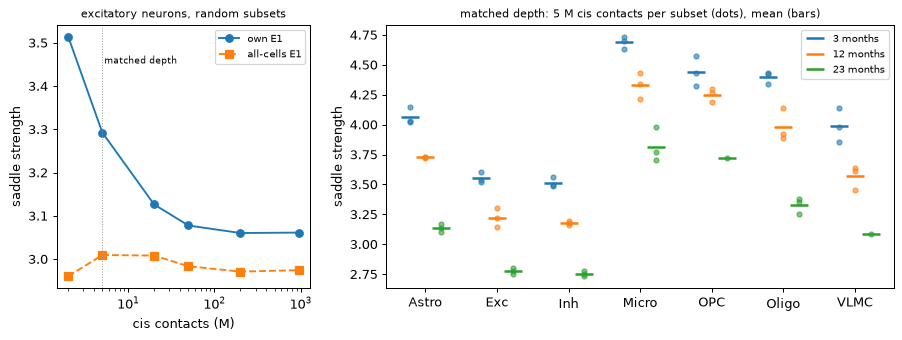

In [8]:
matched = res[res["kind"] == "matched"]
ages = list(cells["age"].cat.categories)
types = list(SHORT.values())
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
a.plot(curve["cis contacts"] / 1e6, curve["strength"], "o-", label="own E1")
a.plot(curve["cis contacts"] / 1e6, curve["strength (all-cells E1)"], "s--", label="all-cells E1")
a.axvline(5, color="0.6", lw=0.8, ls=":"); a.text(5.3, a.get_ylim()[1] * 0.98, "matched depth", fontsize=7, va="top")
a.set_xscale("log"); a.set_xlabel("cis contacts (M)"); a.set_ylabel("saddle strength")
a.set_title("excitatory neurons, random subsets", fontsize=9); a.legend(fontsize=8)
for k, age in enumerate(ages):
    sub = matched[matched["age"] == age]
    x = np.array([types.index(t) for t in sub["cell type"]]) + (k - 1) * 0.22
    b.plot(x, sub["strength"], "o", ms=4, color=f"C{k}", alpha=0.6)
    m = sub.groupby("cell type")["strength"].mean().reindex(types)
    b.plot(np.arange(len(types)) + (k - 1) * 0.22, m, "_", ms=14, mew=2, color=f"C{k}", label=age)
b.set_xticks(range(len(types)), types); b.set_ylabel("saddle strength")
b.set_title("matched depth: 5 M cis contacts per subset (dots), mean (bars)", fontsize=9); b.legend(fontsize=8)
plt.show()

In [9]:
table = matched.groupby(["cell type", "age"], observed=True)["strength"].agg(["mean", "std", "count"])
table = table.apply(lambda r: f"{r['mean']:.2f} ± {r['std']:.2f} ({r['count']:.0f})" if r["count"] > 1
                    else f"{r['mean']:.2f} (1)", axis=1)
table.unstack("age").reindex(types)[ages]               # mean ± SD (subsets)

age,3 months,12 months,23 months
cell type,,,
Astro,4.07 ± 0.07 (3),3.73 ± 0.00 (3),3.13 ± 0.03 (3)
Exc,3.55 ± 0.04 (3),3.22 ± 0.08 (3),2.77 ± 0.02 (3)
Inh,3.51 ± 0.04 (3),3.18 ± 0.02 (3),2.75 ± 0.02 (3)
Micro,4.69 ± 0.05 (3),4.33 ± 0.11 (3),3.82 ± 0.14 (3)
OPC,4.44 ± 0.13 (3),4.25 ± 0.06 (3),3.72 (1)
Oligo,4.40 ± 0.05 (3),3.98 ± 0.14 (3),3.33 ± 0.07 (3)
VLMC,3.99 ± 0.14 (3),3.57 ± 0.10 (3),3.08 (1)


**Depth.**  With its own eigenvector, the strength of the excitatory-neuron map rises as the map gets
shallower: within 3 % of the full map from 20 M cis contacts up, +8 % at 5 M, +15 % at 2 M.  The rise comes
from grouping the bins by the eigenvector of the same shallow map: grouped by the all-cells E1 instead, the
strength stays within 2 % at every depth.  Above 50 M the inflation is about 1 %, and every cell-type map of
section 3 has at least 51 M cis contacts, so their differences are not a depth artefact at 1 Mb; at finer
bins, or with smaller groups, they would need the same check.

**Matched depth.**  At 5 M cis contacts per subset the strengths sit a little higher than at full depth (the
depth effect, the same for every group), and the subsets of one group differ little (standard deviations up
to 0.15).  Within every age the two neuron types have the lowest strength, at least 0.3 below every other cell
type, and microglia the highest — the pattern of the full-depth maps.  Within every cell type the strength also falls with age, 3 > 12 > 23 months, by
0.7–1.1 from 3 to 23 months.  That second difference needs a caution: in this dataset the ages are separate
samples, and the older the sample, the more trans contacts and the fewer short-range contacts its cells have,
in every cell type and most at 23 months (below) — a sign of more random ligation products, which flatten a
saddle as well.  Matching the number of contacts does not match that, so here the age trend is a difference
between samples, not yet an effect of ageing.

In [10]:
cells.groupby(["cell_type", "age"], observed=True)[["frac_trans", "frac_cis_le20kb"]].median() \
    .unstack("age").round(2).rename(index=SHORT)

frac_trans                     frac_cis_le20kb                    
age         3 months 12 months 23 months        3 months 12 months 23 months
cell_type                                                                   
Astro           0.24      0.27      0.40            0.21      0.18      0.10
Exc             0.22      0.26      0.37            0.24      0.21      0.13
Inh             0.24      0.27      0.40            0.24      0.21      0.13
Micro           0.24      0.27      0.39            0.22      0.19      0.10
OPC             0.25      0.29      0.41            0.21      0.18      0.11
Oligo           0.24      0.28      0.39            0.21      0.18      0.10
VLMC            0.26      0.29      0.40            0.20      0.17      0.09

In [11]:
print(f"total run time {(time.time() - T0) / 60:.1f} min")

total run time 0.6 min


## Notes

- **Matched depth**: compare strengths (and call structures) between groups at the same number of contacts;
  `sample_cells_by_depth` draws the subsets and `pseudobulk(cd, sets["set"])` makes them in one pass over the
  maps.  Replicate subsets of each group show how much of a difference is sampling.
- **Phasing**: on a species or resolution where the leading eigenvector is not always the compartment one,
  orient every group by one shared reference (here the all-cells E1, itself oriented by gene density:
  `phasing="compartments.all"`) with `sort_by_phasing=True`, and check `phasing_r1` per chromosome in
  `cd.results[<key>.eigvals]`.
- **Loops and domains**: cell-type maps of a few hundred million contacts at 1 Mb do not resolve them; a
  pseudo-bulk at finer bins can be scored for known loops with `uc.tl.pileup` (the
  `hic_structures` tutorial), which works at depths where loop calling fails.
- **Data**: Wu et al. 2025, *Cell Discov.* (doi:10.1038/s41421-025-00770-8), GEO GSE285812; pseudo-bulk
  summing of single-cell maps by cell type as in e.g. Lee et al. 2019 (*Nat Methods* 16:999) and Tan et al.
  2021 (*Cell* 184:741).

## Next steps

- `hic_structures` — compartments, domains, loops and pileups on a bulk map, against published calls.
- `higashi_embedding`, `cell_embeddings` — grouping cells by their contact maps.